In [38]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_digits, make_moons
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.exceptions import ConvergenceWarning

DATA_DIR = Path('data')
BAI_TAP_DIR = Path('baitap09')
DATA_DIR.mkdir(exist_ok=True)
BAI_TAP_DIR.mkdir(exist_ok=True)

pd.set_option('display.float_format', '{:.6f}'.format)
print('Thư mục làm việc:', Path.cwd())
print('File đã có trong data/:', [p.name for p in DATA_DIR.glob('*.csv')])
print('Chú ý: phải tải 2 CSV gốc vào data/ trên Colab nếu muốn chạy đúng dữ liệu giảng viên.')

Thư mục làm việc: /content
File đã có trong data/: ['hai_vang_trang.csv', 'sinh_vien_mo_rong.csv', 'xor.csv']
Chú ý: phải tải 2 CSV gốc vào data/ trên Colab nếu muốn chạy đúng dữ liệu giảng viên.


In [28]:


def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

# Phần 1: một nơ-ron với hàm sigmoid, chính là hồi quy logistic
w = np.array([0.8, -0.5, 0.3])
b = -0.2
x = np.array([2.0, 1.0, 3.0])
z = w @ x + b

print("Mot no-ron:")
print(f" z = {w[0]}*{x[0]} + ({w[1]})*{x[1]} + {w[2]}*{x[2]} + ({b}) = {z:.2f}")
print(f" a = sigmoid(z) = {sigmoid(z):.4f}")
print()

# Phần 2: mạng 2 đầu vào, 2 nơ-ron ẩn ReLU, 1 nơ-ron ra
# Trọng số tự đặt để mạng tính đúng phép XOR
W1 = np.array([[1.0, 1.0],  # cột 1: trọng số vào nơ-ron ẩn h1
              [1.0, 1.0]]) # cột 2: trọng số vào nơ-ron ẩn h2
b1 = np.array([0.0, -1.0])
W2 = np.array([1.0, -2.0])
b2 = 0.0

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
print("Mang giai XOR:")
print(" x1  x2  h1  h2  y")
for x_val in X:
    h = relu(x_val @ W1 + b1) # lớp ẩn
    y = h @ W2 + b2          # lớp ra
    print(f" {x_val[0]:.0f}   {x_val[1]:.0f}   {h[0]:.0f}   {h[1]:.0f}   {y:.0f}")
print()

# Cả bốn đầu vào cùng lúc bằng phép nhân ma trận
H = relu(X @ W1 + b1)
Y = H @ W2 + b2
print("Tinh ca bang mot lan:", Y)

Mot no-ron:
 z = 0.8*2.0 + (-0.5)*1.0 + 0.3*3.0 + (-0.2) = 1.80
 a = sigmoid(z) = 0.8581

Mang giai XOR:
 x1  x2  h1  h2  y
 0   0   0   0   0
 0   1   1   0   1
 1   0   1   0   1
 1   1   2   1   0

Tinh ca bang mot lan: [0. 1. 1. 0.]


In [29]:

os.makedirs("data", exist_ok=True)

np.random.seed(17)

# Tao 400 diem du lieu XOR
X = np.random.uniform(-1, 1, (400, 2))

# Lop 1: goc tren phai va goc duoi trai
y = ((X[:, 0] > 0) != (X[:, 1] > 0)).astype(int)

df = pd.DataFrame({
    "x1": X[:, 0],
    "x2": X[:, 1],
    "nhan": y
})

df.to_csv("data/xor.csv", index=False)

print("Da tao file data/xor.csv")
print("So diem:", len(df))
display(df.head())

Da tao file data/xor.csv
So diem: 400


,x1,x2,nhan
0,-0.410670,0.061174,1
1,-0.616958,-0.864199,0
2,0.573971,0.312667,0
3,0.275042,0.151206,0
4,-0.921874,-0.284373,0


In [30]:
# 1. XOR
df_xor = pd.read_csv("data/xor.csv")

# 2. Hai vanh trang
df_moon = pd.read_csv("data/hai_vang_trang.csv")

# 3. Sinh vien mo rong
df_sv = pd.read_csv("data/sinh_vien_mo_rong.csv")

# 4. Chu so viet tay
digits = load_digits()

print("XOR:", df_xor.shape)
print("Hai vanh trang:", df_moon.shape)
print("Sinh vien:", df_sv.shape)
print("Chu so viet tay:", digits.data.shape)

XOR: (400, 3)
Hai vanh trang: (300, 3)
Sinh vien: (120, 4)
Chu so viet tay: (1797, 64)


In [31]:
if not os.path.exists("data/xor.csv"):
    rng = np.random.RandomState(17)
    X_data = rng.uniform(-1, 1, (400, 2))
    y_data = ((X_data[:, 0] > 0) != (X_data[:, 1] > 0)).astype(int)

    pd.DataFrame({
        "x1": X_data[:, 0],
        "x2": X_data[:, 1],
        "nhan": y_data
    }).to_csv("data/xor.csv", index=False)

# Doc du lieu
df = pd.read_csv("data/xor.csv")

X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = LogisticRegression().fit(X_tr, y_tr)
print(f"Hoi quy logistic: {accuracy_score(y_te, lr.predict(X_te)):.4f}")
print()

print("So no-ron an   So tham so   Tap hoc   Tap kiem tra")

for so in [1, 2, 4, 8]:
    mlp = MLPClassifier(
        hidden_layer_sizes=(so,),
        solver="lbfgs",
        max_iter=5000,
        random_state=0
    )

    mlp.fit(X_tr, y_tr)

    so_ts = sum(w.size for w in mlp.coefs_)
    so_ts += sum(b.size for b in mlp.intercepts_)

    a_hoc = accuracy_score(y_tr, mlp.predict(X_tr))
    a_kt = accuracy_score(y_te, mlp.predict(X_te))

    print(f"{so:12d}   {so_ts:10d}   {a_hoc:.4f}   {a_kt:.4f}")

Hoi quy logistic: 0.5500

So no-ron an   So tham so   Tap hoc   Tap kiem tra
           1            5   0.6667   0.6500
           2            9   0.7067   0.7000
           4           17   0.8433   0.8400
           8           33   1.0000   0.9600


In [26]:
df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

def mang(lop_an, alpha):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=lop_an, alpha=alpha,
                      solver="lbfgs", max_iter=20000, random_state=0),
    )

print("Ba mang tap hoc tap kiem tra")
for ten, lop_an, alpha in [("(2,), alpha 1e-4", (2,), 1e-4),
                            ("(100, 100), 1e-5", (100, 100), 1e-5),
                            ("(100, 100), 1.0", (100, 100), 1.0)]:
    m = mang(lop_an, alpha).fit(X_tr, y_tr)
    print(f" {ten:18s} {accuracy_score(y_tr, m.predict(X_tr)):.4f}"
          f" {accuracy_score(y_te, m.predict(X_te)):.4f}")
print()

# Chọn alpha bằng kiểm định chéo, chỉ trên tập học
print("alpha kiem dinh cheo")
diem = {}
for alpha in [1e-5, 1e-3, 0.1, 1.0, 3.0, 10.0]:
    diem[alpha] = cross_val_score(mang((100, 100), alpha),
                                 X_tr, y_tr, cv=5).mean()
    print(f" {alpha:<8} {diem[alpha]:.4f}")

a_tot = max(diem, key=diem.get)
m = mang((100, 100), a_tot).fit(X_tr, y_tr)
print(f"alpha tot nhat = {a_tot}, tap kiem tra "
      f"{accuracy_score(y_te, m.predict(X_te)):.4f}")

Ba mang tap hoc tap kiem tra
 (2,), alpha 1e-4   0.8444 0.8533
 (100, 100), 1e-5   1.0000 0.7733
 (100, 100), 1.0    0.8844 0.9067

alpha kiem dinh cheo
 1e-05    0.7822
 0.001    0.7822
 0.1      0.7689
 1.0      0.8578
 3.0      0.8400
 10.0     0.8356
alpha tot nhat = 1.0, tap kiem tra 0.9067


In [33]:
df = pd.read_csv("data/sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

tho = MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                    random_state=0).fit(X_tr, y_tr)
chuan = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                  random_state=0),
).fit(X_tr, y_tr)

print(f"Doan bua ca lop qua : {y_te.mean():.4f}")
print(f"Khong chuan hoa : "
      f"{accuracy_score(y_te, tho.predict(X_te)):.4f}")
print(f"Co chuan hoa : "
      f"{accuracy_score(y_te, chuan.predict(X_te)):.4f}")
print()

# Mạng không chuẩn hoá đoán ra sao
du = tho.predict(X_te)
print("Khong chuan hoa, so ban doan qua:", du.sum(), "tren", len(du))

Doan bua ca lop qua : 0.6000
Khong chuan hoa : 0.4000
Co chuan hoa : 0.9000

Khong chuan hoa, so ban doan qua: 0 tren 30


In [37]:
X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mang = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                  random_state=0),
).fit(X_tr, y_tr)
mlp = mang[-1]
print("Kich thuoc cac ma tran trong so:",
      [w.shape for w in mlp.coefs_])
so_ts = sum(w.size for w in mlp.coefs_)
so_ts += sum(b.size for b in mlp.intercepts_)
print("Tong so tham so:", so_ts)
print("So vong hoc:", mlp.n_iter_)
mm = mlp.loss_curve_
print(f"Mat mat vong 1: {mm[0]:.4f}, vong 10: {mm[9]:.4f},"
      f" vong cuoi: {mm[-1]:.4f}")
print()

du = mang.predict(X_te)
print(f"Accuracy tren tap kiem tra: {accuracy_score(y_te, du):.4f}")
sai = np.flatnonzero(du != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f" anh {i:3d}: that la {y_te[i]}, doan la {du[i]}")
print()

# Dừng sớm: giữ riêng 10% tập học để theo dõi
dung_som = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                  early_stopping=True, random_state=0),
).fit(X_tr, y_tr)
print("Dung som sau", dung_som[-1].n_iter_, "vong, accuracy",
      f"{accuracy_score(y_te, dung_som.predict(X_te)):.4f}")
print()

# So với các mô hình đã học, cùng tập học và tập kiểm tra
khac = {
    "Logistic co chuan hoa": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN, k = 5": KNeighborsClassifier(),
    "SVM kernel RBF": SVC(),
}
for ten, mh in khac.items():
    acc = accuracy_score(y_te, mh.fit(X_tr, y_tr).predict(X_te))
    print(f"{ten:22s} {acc:.4f}")

Kich thuoc cac ma tran trong so: [(64, 100), (100, 10)]
Tong so tham so: 7510
So vong hoc: 144
Mat mat vong 1: 2.5206, vong 10: 0.4448, vong cuoi: 0.0052

Accuracy tren tap kiem tra: 0.9844
So anh doan sai: 7 tren 450
 anh   6: that la 9, doan la 3
 anh  61: that la 5, doan la 7
 anh  77: that la 2, doan la 1
 anh  85: that la 9, doan la 7
 anh 276: that la 8, doan la 2
 anh 428: that la 7, doan la 9
 anh 443: that la 4, doan la 7

Dung som sau 44 vong, accuracy 0.9578

Logistic co chuan hoa  0.9711
KNN, k = 5             0.9867
SVM kernel RBF         0.9911


Bài **1**

In [39]:
# Chuẩn bị đúng bộ XOR (không ghi đè nếu đã có file của giảng viên)
file_xor = DATA_DIR / 'xor.csv'
if file_xor.exists():
    df_xor = pd.read_csv(file_xor)
    nguon_xor = 'CSV có sẵn: data/xor.csv'
else:
    rng = np.random.RandomState(17)
    diem = rng.uniform(-1, 1, size=(400, 2))
    nhan = ((diem[:, 0] > 0) != (diem[:, 1] > 0)).astype(int)
    df_xor = pd.DataFrame({'x1': diem[:, 0], 'x2': diem[:, 1], 'nhan': nhan})
    df_xor.to_csv(file_xor, index=False)
    nguon_xor = '400 điểm XOR mô phỏng tự tạo (chưa phải file gốc giảng viên)'

assert {'x1','x2','nhan'}.issubset(df_xor.columns)
X_xor = df_xor[['x1', 'x2']]
y_xor = df_xor['nhan']
X_xor_hoc, X_xor_kt, y_xor_hoc, y_xor_kt = train_test_split(
    X_xor, y_xor, test_size=0.25, random_state=17, stratify=y_xor
)

mang_xor = MLPClassifier(hidden_layer_sizes=(8,), activation='relu',
                         solver='lbfgs', max_iter=5000, random_state=0)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    mang_xor.fit(X_xor_hoc, y_xor_hoc)

# Lấy trọng số/chệch mà mạng đã học
W1, W2 = mang_xor.coefs_
b1, b2 = mang_xor.intercepts_

# Tự tính lan truyền tiến cho 5 điểm đầu tập kiểm tra, CHỈ bằng NumPy
X_5 = X_xor_kt.iloc[:5].to_numpy()
Z1 = X_5 @ W1 + b1
H1 = np.maximum(0.0, Z1)  # ReLU: đầu ra 8 nơ-ron ẩn
Z2 = H1 @ W2 + b2
P_tu_tinh = (1 / (1 + np.exp(-np.clip(Z2, -500, 500)))).ravel()  # sigmoid

# So sánh với mô hình sklearn, cột lớp 1
P_sklearn = mang_xor.predict_proba(X_xor_kt.iloc[:5])[:, 1]
sai_lech = np.abs(P_tu_tinh - P_sklearn)
bang_b1 = X_xor_kt.iloc[:5].reset_index(drop=True).copy()
bang_b1['P(tự tính)'] = P_tu_tinh
bang_b1['P(sklearn)'] = P_sklearn
bang_b1['Sai lệch'] = sai_lech

print('Dữ liệu:', nguon_xor)
print('Kích thước W1, W2:', W1.shape, W2.shape)
print('Accuracy kiểm tra:', f'{accuracy_score(y_xor_kt, mang_xor.predict(X_xor_kt)):.4f}')
display(bang_b1)
print(f'Sai lệch lớn nhất: {sai_lech.max():.12e}')
print('Hai cách tính khớp:', np.allclose(P_tu_tinh, P_sklearn, atol=1e-10, rtol=0))
assert np.allclose(P_tu_tinh, P_sklearn, atol=1e-10, rtol=0)
print('NHẬN XÉT: Các giá trị gần như trùng nhau; dự đoán của MLP chính là các phép nhân ma trận,')
print('cộng bias và áp dụng ReLU ở lớp ẩn, sigmoid ở lớp đầu ra theo đúng trọng số đã học.')

Dữ liệu: CSV có sẵn: data/xor.csv
Kích thước W1, W2: (2, 8) (8, 1)
Accuracy kiểm tra: 0.9600


,x1,x2,P(tự tính),P(sklearn),Sai lệch
0,-0.488435,-0.449165,0.000000,0.000000,0.000000
1,-0.102100,0.794575,1.000000,1.000000,0.000000
2,0.484556,0.077794,0.000000,0.000000,0.000000
3,-0.092525,-0.024645,0.000017,0.000017,0.000000
4,-0.657611,0.428949,1.000000,1.000000,0.000000


Sai lệch lớn nhất: 0.000000000000e+00
Hai cách tính khớp: True
NHẬN XÉT: Các giá trị gần như trùng nhau; dự đoán của MLP chính là các phép nhân ma trận,
cộng bias và áp dụng ReLU ở lớp ẩn, sigmoid ở lớp đầu ra theo đúng trọng số đã học.


Bài 2

In [40]:
# 4 trường hợp của bảng chân trị XOR
X_nhi_phan = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
x1 = X_nhi_phan[:, 0]
x2 = X_nhi_phan[:, 1]

# Hai nơ-ron ẩn ReLU
h1 = np.maximum(0, x1 - x2)
h2 = np.maximum(0, x2 - x1)
y_mang = h1 + h2

# XOR đúng theo logic, làm chuẩn so sánh
y_xor_chuan = np.logical_xor(x1, x2).astype(int)
bang_b2 = pd.DataFrame({
    'x1': x1, 'x2': x2, 'h1': h1, 'h2': h2,
    'y của mạng': y_mang, 'XOR chuẩn': y_xor_chuan,
    'Đúng?': y_mang == y_xor_chuan
})
display(bang_b2)
assert np.array_equal(y_mang, y_xor_chuan)
print('KẾT LUẬN: Mạng đúng với cả bốn tổ hợp XOR.')
print('GIẢI THÍCH: Nếu x1=x2, cả hai hiệu không dương nên h1=h2=0 và y=0.')
print('Nếu x1 khác x2, đúng một hiệu bằng +1 nên một nơ-ron phát 1, nơ-ron kia phát 0, y=1.')
print('Với x1, x2 thuộc {0,1}, y=|x1-x2| chính là phép XOR.')

,x1,x2,h1,h2,y của mạng,XOR chuẩn,Đúng?
0,0,0,0,0,0,0,True
1,0,1,0,1,1,1,True
2,1,0,1,0,1,1,True
3,1,1,0,0,0,0,True


KẾT LUẬN: Mạng đúng với cả bốn tổ hợp XOR.
GIẢI THÍCH: Nếu x1=x2, cả hai hiệu không dương nên h1=h2=0 và y=0.
Nếu x1 khác x2, đúng một hiệu bằng +1 nên một nơ-ron phát 1, nơ-ron kia phát 0, y=1.
Với x1, x2 thuộc {0,1}, y=|x1-x2| chính là phép XOR.


Bài 3

In [41]:
file_moon = DATA_DIR / 'hai_vang_trang.csv'
if file_moon.exists():
    df_moon = pd.read_csv(file_moon)
    nguon_moon = 'CSV GỐC: data/hai_vang_trang.csv'
else:
    # Chỉ dùng để notebook chạy được khi chưa có CSV trên môi trường này
    X_demo, y_demo = make_moons(n_samples=400, noise=0.25, random_state=17)
    df_moon = pd.DataFrame({'x1': X_demo[:, 0], 'x2': X_demo[:, 1], 'nhan': y_demo})
    nguon_moon = 'DỮ LIỆU MINH HỌA make_moons, KHÔNG PHẢI CSV GỐC'

assert {'x1','x2','nhan'}.issubset(df_moon.columns)
X_moon = df_moon[['x1', 'x2']]
y_moon = df_moon['nhan']
X_m_hoc, X_m_kt, y_m_hoc, y_m_kt = train_test_split(
    X_moon, y_moon, test_size=0.25, random_state=17, stratify=y_moon
)

ket_qua_b3 = []
for kich_hoat in ['logistic', 'tanh', 'relu']:
    mang = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(100, 100), alpha=1.0,
                      activation=kich_hoat, solver='lbfgs',
                      max_iter=20000, random_state=0)
    )
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        mang.fit(X_m_hoc, y_m_hoc)
    ket_qua_b3.append({
        'Activation': kich_hoat,
        'Accuracy tập học': accuracy_score(y_m_hoc, mang.predict(X_m_hoc)),
        'Accuracy tập kiểm tra': accuracy_score(y_m_kt, mang.predict(X_m_kt))
    })

bang_b3 = pd.DataFrame(ket_qua_b3)
print('Dữ liệu:', nguon_moon)
display(bang_b3)
diem_cao_nhat = bang_b3['Accuracy tập kiểm tra'].max()
ham_tot_nhat = bang_b3.loc[np.isclose(bang_b3['Accuracy tập kiểm tra'], diem_cao_nhat), 'Activation'].tolist()
print(f'NHẬN XÉT: Tốt nhất trên tập kiểm tra: {", ".join(ham_tot_nhat)} ({diem_cao_nhat:.4f}).')
print('Chọn theo accuracy kiểm tra; accuracy tập học cao chưa chắc tổng quát hóa tốt nhất.')
if not file_moon.exists():
    print('CHÚ Ý: Thay bằng CSV gốc rồi chạy lại để kết luận theo dữ liệu giảng viên.')

Dữ liệu: CSV GỐC: data/hai_vang_trang.csv


,Activation,Accuracy tập học,Accuracy tập kiểm tra
0,logistic,0.840000,0.853333
1,tanh,0.871111,0.906667
2,relu,0.884444,0.906667


NHẬN XÉT: Tốt nhất trên tập kiểm tra: tanh, relu (0.9067).
Chọn theo accuracy kiểm tra; accuracy tập học cao chưa chắc tổng quát hóa tốt nhất.


Bài 4

,learning_rate_init,n_iter_,Loss cuối,Accuracy kiểm tra
0,0.000100,582,0.018928,0.988889
1,0.001000,144,0.005210,0.984444
2,0.010000,38,0.001077,0.977778
3,0.100000,30,0.123004,0.966667


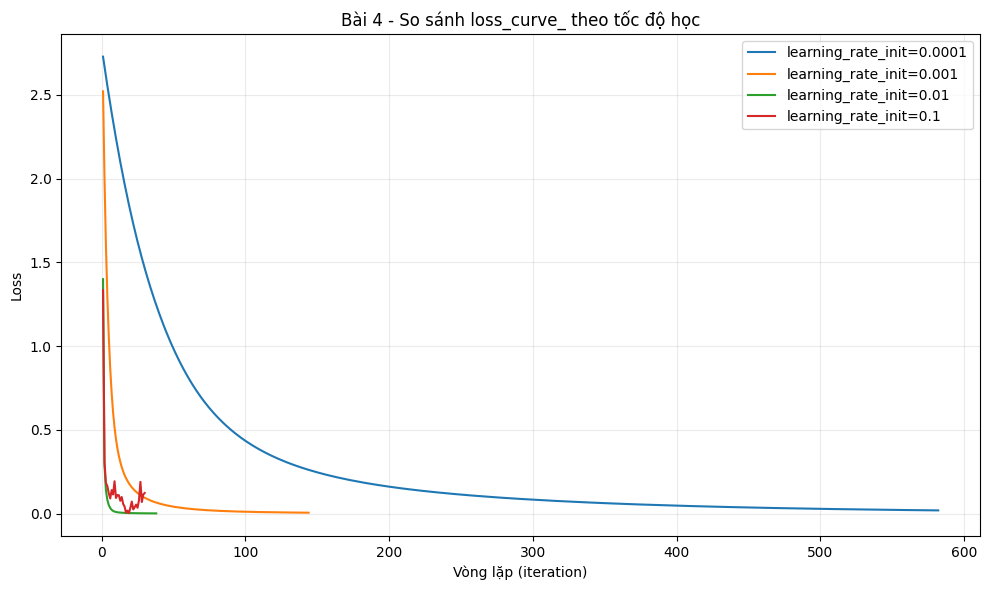

Đã lưu hình: baitap09/toc_do_hoc.png
NHẬN XÉT: Learning rate có accuracy kiểm tra cao nhất trong thí nghiệm: 0.0001 (0.9889).
Tốc độ quá nhỏ: loss giảm chậm, cần nhiều vòng và có thể chưa học đủ trong giới hạn max_iter.
Tốc độ quá lớn: cập nhật bước quá dài, loss có thể dao động/khó ổn định, làm giảm độ chính xác.
Nhìn đường loss và bảng kết quả thực tế để kết luận mức độ ảnh hưởng ở lần chạy này.


In [42]:
X_digits, y_digits = load_digits(return_X_y=True)
X_d_hoc, X_d_kt, y_d_hoc, y_d_kt = train_test_split(
    X_digits, y_digits, test_size=0.25, random_state=17, stratify=y_digits
)

bang_b4_list = []
loss_theo_toc_do = {}
for toc_do in [0.0001, 0.001, 0.01, 0.1]:
    mo_hinh = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(100,), learning_rate_init=toc_do,
                      max_iter=1000, random_state=0)
    )
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        mo_hinh.fit(X_d_hoc, y_d_hoc)
    mang_da_hoc = mo_hinh.named_steps['mlpclassifier']
    loss_theo_toc_do[toc_do] = mang_da_hoc.loss_curve_.copy()
    bang_b4_list.append({
        'learning_rate_init': toc_do,
        'n_iter_': mang_da_hoc.n_iter_,
        'Loss cuối': mang_da_hoc.loss_curve_[-1],
        'Accuracy kiểm tra': accuracy_score(y_d_kt, mo_hinh.predict(X_d_kt))
    })

bang_b4 = pd.DataFrame(bang_b4_list)
display(bang_b4)

plt.figure(figsize=(10, 6))
for toc_do, duong_loss in loss_theo_toc_do.items():
    plt.plot(range(1, len(duong_loss)+1), duong_loss,
             label=f'learning_rate_init={toc_do}')
plt.title('Bài 4 - So sánh loss_curve_ theo tốc độ học')
plt.xlabel('Vòng lặp (iteration)')
plt.ylabel('Loss')
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
duong_dan_hinh = BAI_TAP_DIR / 'toc_do_hoc.png'
plt.savefig(duong_dan_hinh, dpi=180, bbox_inches='tight')
plt.show()
print('Đã lưu hình:', duong_dan_hinh)

best_row_b4 = bang_b4.loc[bang_b4['Accuracy kiểm tra'].idxmax()]
print(f'NHẬN XÉT: Learning rate có accuracy kiểm tra cao nhất trong thí nghiệm: '
      f'{best_row_b4["learning_rate_init"]} ({best_row_b4["Accuracy kiểm tra"]:.4f}).')
print('Tốc độ quá nhỏ: loss giảm chậm, cần nhiều vòng và có thể chưa học đủ trong giới hạn max_iter.')
print('Tốc độ quá lớn: cập nhật bước quá dài, loss có thể dao động/khó ổn định, làm giảm độ chính xác.')
print('Nhìn đường loss và bảng kết quả thực tế để kết luận mức độ ảnh hưởng ở lần chạy này.')

Bài5

In [43]:
mo_hinh_grid = make_pipeline(
    StandardScaler(),
    MLPClassifier(max_iter=400, early_stopping=True,
                  n_iter_no_change=20, random_state=0)
)
luoi = {
    'mlpclassifier__hidden_layer_sizes': [(10,), (50,), (100,), (50, 50)],
    'mlpclassifier__alpha': [0.0001, 0.01, 1.0]
}

tim_kiem = GridSearchCV(
    estimator=mo_hinh_grid, param_grid=luoi,
    scoring='accuracy', cv=3, n_jobs=1, refit=True,
    return_train_score=False
)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    tim_kiem.fit(X_d_hoc, y_d_hoc)

ket_qua_cv = pd.DataFrame(tim_kiem.cv_results_)[[
    'param_mlpclassifier__hidden_layer_sizes',
    'param_mlpclassifier__alpha',
    'mean_test_score', 'std_test_score', 'rank_test_score'
]].sort_values(['rank_test_score','mean_test_score'], ascending=[True,False])
print('Bảng 12 cấu hình (xếp theo kết quả cross-validation):')
display(ket_qua_cv.reset_index(drop=True))

accuracy_mlp = accuracy_score(y_d_kt, tim_kiem.predict(X_d_kt))
svm = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
svm.fit(X_d_hoc, y_d_hoc)
accuracy_svm = accuracy_score(y_d_kt, svm.predict(X_d_kt))

print('Cặp tham số tốt nhất:', tim_kiem.best_params_)
print(f'Accuracy CV tốt nhất: {tim_kiem.best_score_:.4f}')
print(f'Accuracy MLP trên tập kiểm tra: {accuracy_mlp:.4f}')
print(f'Accuracy SVM trên tập kiểm tra: {accuracy_svm:.4f}')
print('NHẬN XÉT:', 'MLP vượt SVM.' if accuracy_mlp > accuracy_svm
      else ('MLP bằng SVM.' if accuracy_mlp == accuracy_svm else 'MLP chưa vượt SVM.'))
print('Đây là so sánh trên cùng phép chia train/test, không dùng tập test để chọn tham số.')

Bảng 12 cấu hình (xếp theo kết quả cross-validation):


,param_mlpclassifier__hidden_layer_sizes,param_mlpclassifier__alpha,mean_test_score,std_test_score,rank_test_score
0,"(50, 50)",0.000100,0.947290,0.005556,1
1,"(50, 50)",0.010000,0.946548,0.005455,2
2,"(100,)",0.010000,0.945063,0.018215,3
3,"(100,)",0.000100,0.944321,0.013729,4
4,"(100,)",1.000000,0.941351,0.014699,5
5,"(50, 50)",1.000000,0.941351,0.004576,5
6,"(50,)",0.010000,0.938382,0.011691,7
7,"(50,)",0.000100,0.937639,0.011356,8
8,"(50,)",1.000000,0.934670,0.005846,9
9,"(10,)",0.010000,0.881960,0.028347,10


Cặp tham số tốt nhất: {'mlpclassifier__alpha': 0.0001, 'mlpclassifier__hidden_layer_sizes': (50, 50)}
Accuracy CV tốt nhất: 0.9473
Accuracy MLP trên tập kiểm tra: 0.9333
Accuracy SVM trên tập kiểm tra: 0.9778
NHẬN XÉT: MLP chưa vượt SVM.
Đây là so sánh trên cùng phép chia train/test, không dùng tập test để chọn tham số.


Bài 6

Dữ liệu: DỮ LIỆU GIÁ NHÀ MINH HỌA (giá giả định tính bằng tỷ đồng)


,Mô hình,MAE tập kiểm tra,Giá dự đoán nhà 250 m²
0,LinearRegression,0.128213,8.208131
1,MLPRegressor (20 nơ-ron),0.220998,10.077347


Dải diện tích dữ liệu gốc/minh họa: 40.0 - 180.0 m²
Mô hình MAE thấp hơn: LinearRegression
250 m² nằm NGOÀI khoảng diện tích tập học: đây là dự đoán NGOẠI SUY.
NHẬN XÉT: Mạng MLP không chắc ngoại suy tốt như đường thẳng; đường thẳng duy trì xu thế
tuyến tính, còn MLP học dạng hàm phi tuyến từ vùng dữ liệu đã thấy. Không thể chỉ dựa
vào MAE tập kiểm tra trong khoảng học để bảo đảm dự đoán 250 m² đáng tin cậy.
CẢNH BÁO: Đây chỉ là kết quả minh họa. Để nộp Bài 6, cần thay bằng dữ liệu giá nhà của Bài 1.


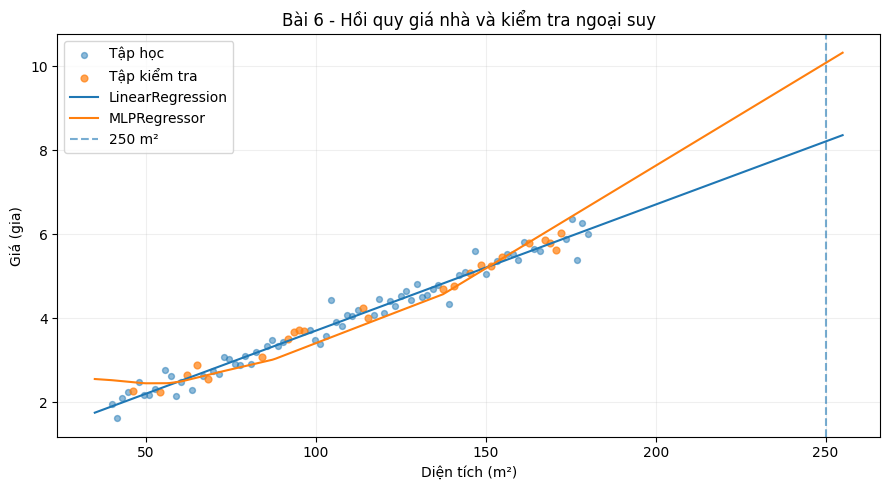

In [44]:
file_gia_nha = DATA_DIR / 'gia_nha.csv'
if file_gia_nha.exists():
    df_nha = pd.read_csv(file_gia_nha)
    cot_dien_tich = next((c for c in ['dien_tich', 'dien_tich_m2', 'dien_tich_nha',
                                     'area', 'area_m2', 'm2'] if c in df_nha.columns), None)
    cot_gia = next((c for c in ['gia', 'gia_nha', 'gia_ban', 'gia_ty',
                               'price', 'price_billion'] if c in df_nha.columns), None)
    if cot_dien_tich is None or cot_gia is None:
        raise ValueError(f'Chưa xác định được cột diện tích/giá. Các cột hiện có: {list(df_nha.columns)}')
    nguon_nha = f'CSV GỐC: {file_gia_nha} ({cot_dien_tich} -> {cot_gia})'
else:
    # Dữ liệu thay thế chỉ để minh họa cách giải; KHÔNG phải bộ giá nhà của bài 1
    rng_nha = np.random.RandomState(17)
    dien_tich_demo = np.linspace(40, 180, 90)
    gia_demo = 0.7 + 0.03 * dien_tich_demo + rng_nha.normal(0, 0.18, 90)
    df_nha = pd.DataFrame({'dien_tich': dien_tich_demo, 'gia': gia_demo})
    cot_dien_tich, cot_gia = 'dien_tich', 'gia'
    nguon_nha = 'DỮ LIỆU GIÁ NHÀ MINH HỌA (giá giả định tính bằng tỷ đồng)'

X_nha = df_nha[[cot_dien_tich]].apply(pd.to_numeric, errors='coerce')
y_nha = pd.to_numeric(df_nha[cot_gia], errors='coerce')
hop_le = X_nha.notna().all(axis=1) & y_nha.notna()
X_nha, y_nha = X_nha.loc[hop_le], y_nha.loc[hop_le]
if len(X_nha) < 8:
    raise ValueError('Cần ít nhất 8 dòng số liệu giá nhà hợp lệ.')

X_n_hoc, X_n_kt, y_n_hoc, y_n_kt = train_test_split(
    X_nha, y_nha, test_size=0.25, random_state=17
)

hoi_quy_tuyen_tinh = make_pipeline(StandardScaler(), LinearRegression())
mang_hoi_quy = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(20,), max_iter=5000, random_state=0)
)
hoi_quy_tuyen_tinh.fit(X_n_hoc, y_n_hoc)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    mang_hoi_quy.fit(X_n_hoc, y_n_hoc)

mae_tuyen_tinh = mean_absolute_error(y_n_kt, hoi_quy_tuyen_tinh.predict(X_n_kt))
mae_mlp = mean_absolute_error(y_n_kt, mang_hoi_quy.predict(X_n_kt))
dien_tich_can_du_doan = pd.DataFrame({cot_dien_tich: [250.0]})
gia_250_tuyen_tinh = hoi_quy_tuyen_tinh.predict(dien_tich_can_du_doan)[0]
gia_250_mlp = mang_hoi_quy.predict(dien_tich_can_du_doan)[0]

print('Dữ liệu:', nguon_nha)
display(pd.DataFrame({
    'Mô hình': ['LinearRegression', 'MLPRegressor (20 nơ-ron)'],
    'MAE tập kiểm tra': [mae_tuyen_tinh, mae_mlp],
    'Giá dự đoán nhà 250 m²': [gia_250_tuyen_tinh, gia_250_mlp]
}))
print(f'Dải diện tích dữ liệu gốc/minh họa: {X_nha.iloc[:,0].min():.1f} - {X_nha.iloc[:,0].max():.1f} m²')
print('Mô hình MAE thấp hơn:', 'MLPRegressor' if mae_mlp < mae_tuyen_tinh
      else ('LinearRegression' if mae_tuyen_tinh < mae_mlp else 'Hai mô hình bằng nhau'))
if 250 > X_n_hoc.iloc[:, 0].max() or 250 < X_n_hoc.iloc[:, 0].min():
    print('250 m² nằm NGOÀI khoảng diện tích tập học: đây là dự đoán NGOẠI SUY.')
else:
    print('250 m² nằm trong khoảng diện tích tập học: đây là dự đoán NỘI SUY.')
print('NHẬN XÉT: Mạng MLP không chắc ngoại suy tốt như đường thẳng; đường thẳng duy trì xu thế')
print('tuyến tính, còn MLP học dạng hàm phi tuyến từ vùng dữ liệu đã thấy. Không thể chỉ dựa')
print('vào MAE tập kiểm tra trong khoảng học để bảo đảm dự đoán 250 m² đáng tin cậy.')
if not file_gia_nha.exists():
    print('CẢNH BÁO: Đây chỉ là kết quả minh họa. Để nộp Bài 6, cần thay bằng dữ liệu giá nhà của Bài 1.')

# Vẽ hình minh họa: dữ liệu thực, đường hồi quy và vị trí ngoại suy 250 m2
truc_x = np.linspace(min(X_nha.iloc[:,0].min(), 250) - 5,
                     max(X_nha.iloc[:,0].max(), 250) + 5, 220)
truc_du_doan = pd.DataFrame({cot_dien_tich: truc_x})
plt.figure(figsize=(9, 5))
plt.scatter(X_n_hoc.iloc[:,0], y_n_hoc, alpha=0.5, s=18, label='Tập học')
plt.scatter(X_n_kt.iloc[:,0], y_n_kt, alpha=0.7, s=24, label='Tập kiểm tra')
plt.plot(truc_x, hoi_quy_tuyen_tinh.predict(truc_du_doan), label='LinearRegression')
plt.plot(truc_x, mang_hoi_quy.predict(truc_du_doan), label='MLPRegressor')
plt.axvline(250, ls='--', alpha=0.6, label='250 m²')
plt.xlabel('Diện tích (m²)')
plt.ylabel(f'Giá ({cot_gia})')
plt.title('Bài 6 - Hồi quy giá nhà và kiểm tra ngoại suy')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(BAI_TAP_DIR / 'hoi_quy_gia_nha.png', dpi=160, bbox_inches='tight')
plt.show()